Question 1: Comparing Removal and Capping in Employee Data

In [1]:

import pandas as pd
import numpy as np

df = pd.DataFrame({
    "Employee_ID": range(1, 11),
    "Age": [22, 25, 28, 30, 32, 35, 38, 40, 42, 100],
    "Salary": [25000, 28000, 30000, 32000, 35000,
               38000, 42000, 45000, 50000, 500000]
})

# Calculate IQR bounds
def calculate_bounds(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return lower, upper

# Find bounds
age_lower, age_upper = calculate_bounds(df, "Age")
salary_lower, salary_upper = calculate_bounds(df, "Salary")

print("Age Bounds:", age_lower, age_upper)
print("Salary Bounds:", salary_lower, salary_upper)

# Identify outliers
outlier_mask = (
    (df["Age"] < age_lower) |
    (df["Age"] > age_upper) |
    (df["Salary"] < salary_lower) |
    (df["Salary"] > salary_upper)
)

# Dataset after removal
removed_df = df[~outlier_mask].copy()

# Dataset after capping
capped_df = df.copy()

capped_df["Age"] = capped_df["Age"].clip(
    age_lower, age_upper
)

capped_df["Salary"] = capped_df["Salary"].clip(
    salary_lower, salary_upper
)

print("\nOriginal Data:")
print(df)

print("\nRemoved Data:")
print(removed_df)

print("\nCapped Data:")
print(capped_df)


Age Bounds: 12.0 56.0
Salary Bounds: 9875.0 64875.0

Original Data:
   Employee_ID  Age  Salary
0            1   22   25000
1            2   25   28000
2            3   28   30000
3            4   30   32000
4            5   32   35000
5            6   35   38000
6            7   38   42000
7            8   40   45000
8            9   42   50000
9           10  100  500000

Removed Data:
   Employee_ID  Age  Salary
0            1   22   25000
1            2   25   28000
2            3   28   30000
3            4   30   32000
4            5   32   35000
5            6   35   38000
6            7   38   42000
7            8   40   45000
8            9   42   50000

Capped Data:
   Employee_ID  Age  Salary
0            1   22   25000
1            2   25   28000
2            3   28   30000
3            4   30   32000
4            5   32   35000
5            6   35   38000
6            7   38   42000
7            8   40   45000
8            9   42   50000
9           10   56   64875


In [2]:

# Function to calculate statistics
def compare_stats(data):
    return data[["Age", "Salary"]].agg(
        ["mean", "median", "std"]
    )

print("Original Statistics:")
print(compare_stats(df))

print("\nRemoved Statistics:")
print(compare_stats(removed_df))

print("\nCapped Statistics:")
print(compare_stats(capped_df))

print("\nRow Counts:")
print("Original:", len(df))
print("Removed:", len(removed_df))
print("Capped:", len(capped_df))


Original Statistics:
              Age         Salary
mean    39.200000   82500.000000
median  33.500000   36500.000000
std     22.319896  146904.541946

Removed Statistics:
              Age        Salary
mean    32.444444  36111.111111
median  32.000000  35000.000000
std      6.857680   8328.331832

Capped Statistics:
              Age        Salary
mean    34.800000  38987.500000
median  33.500000  36500.000000
std      9.863513  12016.257795

Row Counts:
Original: 10
Removed: 9
Capped: 10




Question 2: Outlier Handling in Retail Sales

Sales Bounds: 762.5 2662.5
Customers Bounds: 14.625 67.625

Removed Days:
[12]

Removed Dataset:
    Day  Sales  Customers
0     1   1200         30
1     2   1350         32
2     3   1400         35
3     4   1500         33
4     5   1600         38
5     6   1550         40
6     7   1700         42
7     8   1800         45
8     9   1900         47
9    10   2100         50
10   11   2500         60

Capped Dataset:
    Day   Sales  Customers
0     1  1200.0     30.000
1     2  1350.0     32.000
2     3  1400.0     35.000
3     4  1500.0     33.000
4     5  1600.0     38.000
5     6  1550.0     40.000
6     7  1700.0     42.000
7     8  1800.0     45.000
8     9  1900.0     47.000
9    10  2100.0     50.000
10   11  2500.0     60.000
11   12  2662.5     67.625

Rows after removal: 11


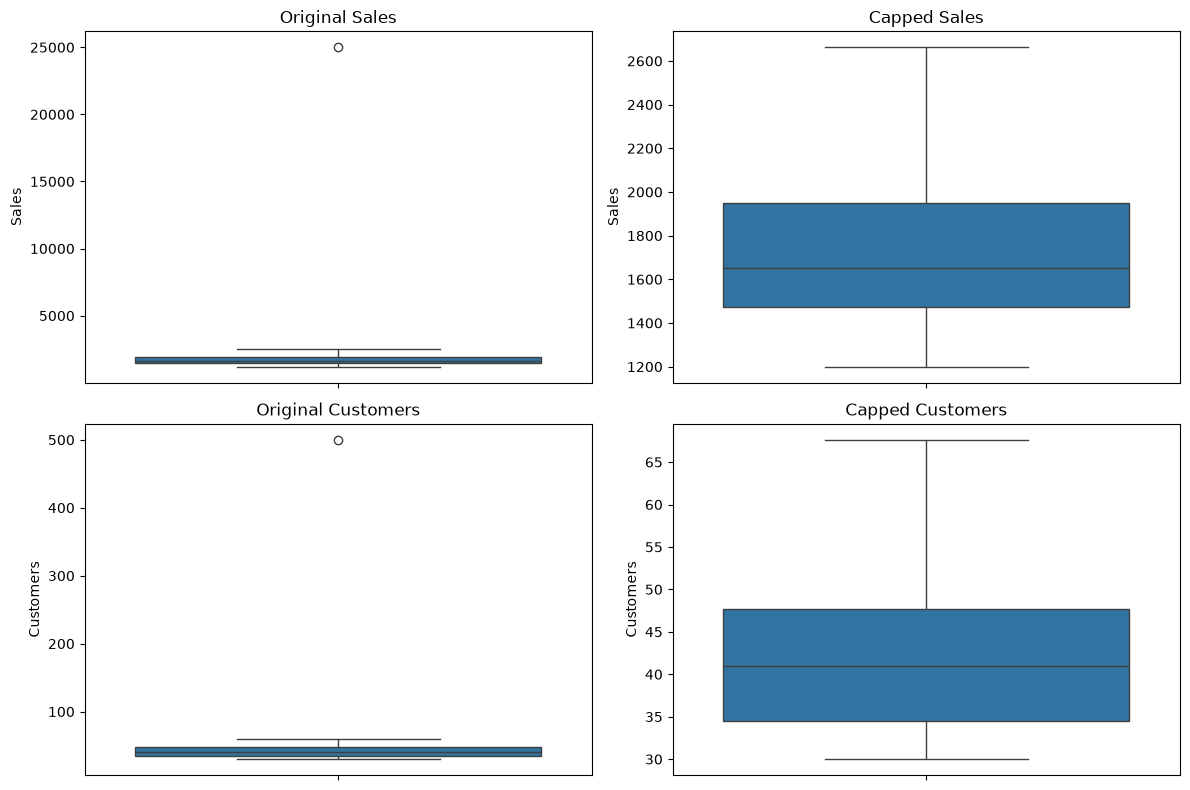

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({
    "Day": range(1, 13),
    "Sales": [1200, 1350, 1400, 1500, 1600, 1550,
              1700, 1800, 1900, 2100, 2500, 25000],
    "Customers": [30, 32, 35, 33, 38, 40,
                  42, 45, 47, 50, 60, 500]
})

# Calculate IQR boundaries
def get_bounds(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return lower, upper

sales_lower, sales_upper = get_bounds(df, "Sales")
customer_lower, customer_upper = get_bounds(
    df, "Customers"
)

print("Sales Bounds:", sales_lower, sales_upper)
print("Customers Bounds:", customer_lower, customer_upper)

# Identify outliers
outlier_mask = (
    (df["Sales"] < sales_lower) |
    (df["Sales"] > sales_upper) |
    (df["Customers"] < customer_lower) |
    (df["Customers"] > customer_upper)
)

# Remove outliers
removed_df = df[~outlier_mask].copy()

# Cap outliers
capped_df = df.copy()

capped_df["Sales"] = capped_df["Sales"].clip(
    sales_lower, sales_upper
)

capped_df["Customers"] = capped_df["Customers"].clip(
    customer_lower, customer_upper
)

print("\nRemoved Days:")
print(df.loc[outlier_mask, "Day"].tolist())

print("\nRemoved Dataset:")
print(removed_df)

print("\nCapped Dataset:")
print(capped_df)

print("\nRows after removal:", len(removed_df))

# Boxplots: Original vs Capped
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.boxplot(y=df["Sales"], ax=axes[0, 0])
axes[0, 0].set_title("Original Sales")

sns.boxplot(y=capped_df["Sales"], ax=axes[0, 1])
axes[0, 1].set_title("Capped Sales")

sns.boxplot(y=df["Customers"], ax=axes[1, 0])
axes[1, 0].set_title("Original Customers")

sns.boxplot(y=capped_df["Customers"], ax=axes[1, 1])
axes[1, 1].set_title("Capped Customers")

plt.tight_layout()
plt.show()


In [4]:

# Original correlation
original_corr = df["Sales"].corr(df["Customers"])

# Removed dataset correlation
removed_corr = removed_df["Sales"].corr(
    removed_df["Customers"]
)

# Capped dataset correlation
capped_corr = capped_df["Sales"].corr(
    capped_df["Customers"]
)

print("Original Correlation:", original_corr)
print("Removed Correlation:", removed_corr)
print("Capped Correlation:", capped_corr)

# Comparison
correlation_df = pd.DataFrame({
    "Dataset": ["Original", "Removed", "Capped"],
    "Correlation": [
        original_corr,
        removed_corr,
        capped_corr
    ]
})

print("\nCorrelation Comparison:")
print(correlation_df)


Original Correlation: 0.9998774409261666
Removed Correlation: 0.9847393058037159
Capped Correlation: 0.9892393777951107

Correlation Comparison:
    Dataset  Correlation
0  Original     0.999877
1   Removed     0.984739
2    Capped     0.989239


Question 3: Handling Outliers Without Losing Customer Records

In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({
    "Customer_ID": range(101, 113),
    "Annual_Spending": [
        8000, 10000, 12000, 15000, 18000, 20000,
        22000, 25000, 30000, 35000, 50000, 800000
    ],
    "Order_Count": [2, 3, 3, 4, 5, 5, 6, 7, 8, 9, 12, 100],
    "Customer_Segment": [
        "Basic", "Basic", "Silver", "Silver",
        "Gold", "Basic", "Silver", "Gold",
        "Gold", "Silver", "Premium", "Premium"
    ]
})

# Calculate IQR bounds
def get_bounds(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return lower, upper

spending_lower, spending_upper = get_bounds(
    df, "Annual_Spending"
)

order_lower, order_upper = get_bounds(
    df, "Order_Count"
)

print("Spending Bounds:", spending_lower, spending_upper)
print("Order Count Bounds:", order_lower, order_upper)

# Detect outliers
outlier_mask = (
    (df["Annual_Spending"] < spending_lower) |
    (df["Annual_Spending"] > spending_upper) |
    (df["Order_Count"] < order_lower) |
    (df["Order_Count"] > order_upper)
)

# Removal dataset
removed_df = df[~outlier_mask].copy()

# Capping dataset
capped_df = df.copy()

capped_df["Annual_Spending"] = capped_df[
    "Annual_Spending"
].clip(spending_lower, spending_upper)

capped_df["Order_Count"] = capped_df[
    "Order_Count"
].clip(order_lower, order_upper)

print("\nRemoved Dataset:")
print(removed_df)

print("\nCapped Dataset:")
print(capped_df)

print("\nOriginal Customer Count:", len(df))
print("Removed Customer Count:", len(removed_df))
print("Capped Customer Count:", len(capped_df))

# Verify all customers are retained after capping
print("\nAll Customers Retained:",
      len(capped_df) == len(df))


Spending Bounds: -11250.0 56750.0
Order Count Bounds: -3.0 15.0

Removed Dataset:
    Customer_ID  Annual_Spending  Order_Count Customer_Segment
0           101             8000            2            Basic
1           102            10000            3            Basic
2           103            12000            3           Silver
3           104            15000            4           Silver
4           105            18000            5             Gold
5           106            20000            5            Basic
6           107            22000            6           Silver
7           108            25000            7             Gold
8           109            30000            8             Gold
9           110            35000            9           Silver
10          111            50000           12          Premium

Capped Dataset:
    Customer_ID  Annual_Spending  Order_Count Customer_Segment
0           101             8000            2            Basic
1           102    

Original Segment Counts:
Customer_Segment
Silver     4
Basic      3
Gold       3
Premium    2
Name: count, dtype: int64

After Removal:
Customer_Segment
Silver     4
Basic      3
Gold       3
Premium    1
Name: count, dtype: int64

Original Spending Statistics:
mean      87083.333333
median    21000.000000
Name: Annual_Spending, dtype: float64

Removed Spending Statistics:
mean      22272.727273
median    20000.000000
Name: Annual_Spending, dtype: float64

Capped Spending Statistics:
mean      25145.833333
median    21000.000000
Name: Annual_Spending, dtype: float64


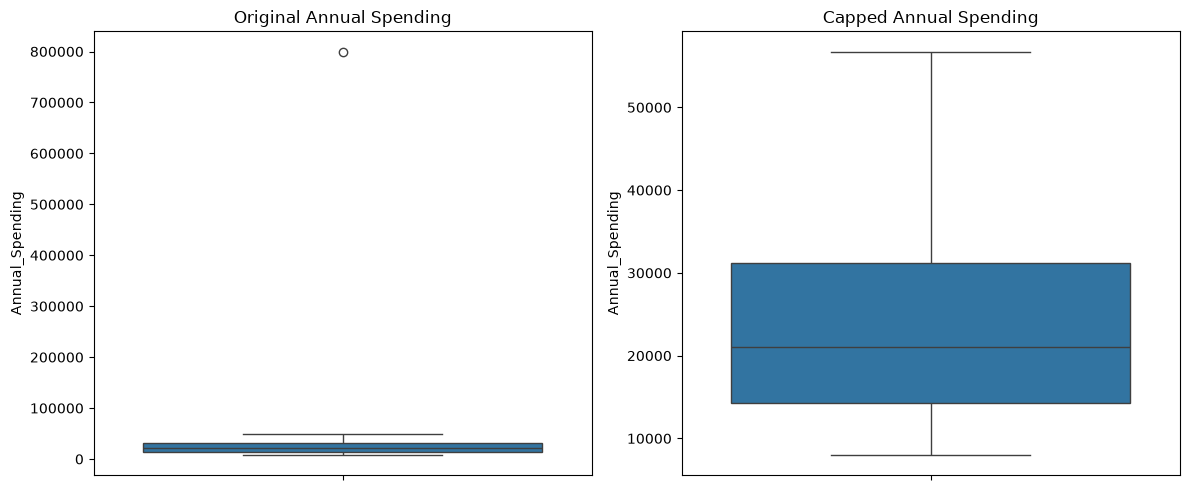

In [6]:

# Customer segment comparison
print("Original Segment Counts:")
print(df["Customer_Segment"].value_counts())

print("\nAfter Removal:")
print(removed_df["Customer_Segment"].value_counts())

# Spending statistics
print("\nOriginal Spending Statistics:")
print(df["Annual_Spending"].agg(
    ["mean", "median"]
))

print("\nRemoved Spending Statistics:")
print(removed_df["Annual_Spending"].agg(
    ["mean", "median"]
))

print("\nCapped Spending Statistics:")
print(capped_df["Annual_Spending"].agg(
    ["mean", "median"]
))

# Visualize spending
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=df["Annual_Spending"])
plt.title("Original Annual Spending")

plt.subplot(1, 2, 2)
sns.boxplot(y=capped_df["Annual_Spending"])
plt.title("Capped Annual Spending")

plt.tight_layout()
plt.show()


Question 4: Building a Reusable Outlier Treatment Function

In [7]:

import pandas as pd
import numpy as np

df = pd.DataFrame({
    "Product": ["A", "B", "C", "D", "E", "F", "G", "H"],
    "Price": [100, 120, 130, 140, 150, 170, 200, 2000],
    "Delivery_Days": [1, 2, 2, 3, 3, 4, 5, 40],
    "Rating": [3.5, 4.0, 4.2, 4.5, 4.1, 3.8, 4.6, 1.0]
})

# Reusable Outlier Treatment Function
def handle_outliers(data, columns, method="remove"):

    # Validate method
    if method not in ["remove", "cap"]:
        raise ValueError(
            "Method must be 'remove' or 'cap'"
        )

    # Validate column names
    for col in columns:
        if col not in data.columns:
            raise ValueError(
                f"Column {col} does not exist"
            )

        if not pd.api.types.is_numeric_dtype(data[col]):
            raise ValueError(
                f"Column {col} must be numerical"
            )

    # Copy original data
    result = data.copy()

    report = []
    outlier_mask = pd.Series(
        False, index=data.index
    )

    for col in columns:

        Q1 = data[col].quantile(0.25)
        Q3 = data[col].quantile(0.75)

        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        # Identify outliers
        mask = (
            (data[col] < lower) |
            (data[col] > upper)
        )

        count = mask.sum()

        outlier_mask |= mask

        # Apply treatment
        if method == "cap":
            result[col] = data[col].clip(
                lower, upper
            )

        report.append({
            "Column": col,
            "Q1": Q1,
            "Q3": Q3,
            "IQR": IQR,
            "Lower_Bound": lower,
            "Upper_Bound": upper,
            "Outlier_Count": count
        })

    # Remove complete rows if required
    if method == "remove":
        result = result.loc[~outlier_mask].copy()

    report_df = pd.DataFrame(report)

    return result, report_df


# Original Data
print("Original Data:")
print(df)

# Apply Removal
removed_df, remove_report = handle_outliers(
    df,
    ["Price", "Delivery_Days", "Rating"],
    method="remove"
)

# Apply Capping
capped_df, cap_report = handle_outliers(
    df,
    ["Price", "Delivery_Days", "Rating"],
    method="cap"
)

print("\nRemoved Dataset:")
print(removed_df)

print("\nRemoval Report:")
print(remove_report)

print("\nCapped Dataset:")
print(capped_df)

print("\nCapping Report:")
print(cap_report)

# Check original dataset remains unchanged
print("\nOriginal Data Unchanged:")
print(df)


Original Data:
  Product  Price  Delivery_Days  Rating
0       A    100              1     3.5
1       B    120              2     4.0
2       C    130              2     4.2
3       D    140              3     4.5
4       E    150              3     4.1
5       F    170              4     3.8
6       G    200              5     4.6
7       H   2000             40     1.0

Removed Dataset:
  Product  Price  Delivery_Days  Rating
0       A    100              1     3.5
1       B    120              2     4.0
2       C    130              2     4.2
3       D    140              3     4.5
4       E    150              3     4.1
5       F    170              4     3.8
6       G    200              5     4.6

Removal Report:
          Column       Q1       Q3    IQR  Lower_Bound  Upper_Bound  \
0          Price  127.500  177.500  50.00       52.500      252.500   
1  Delivery_Days    2.000    4.250   2.25       -1.375        7.625   
2         Rating    3.725    4.275   0.55        2.900   

Original Rows: 8
Removed Rows: 7
Capped Rows: 8

Original Statistics:
             Price  Delivery_Days    Rating
count     8.000000       8.000000  8.000000
mean    376.250000       7.500000  3.712500
std     656.809116      13.190906  1.151939
min     100.000000       1.000000  1.000000
25%     127.500000       2.000000  3.725000
50%     145.000000       3.000000  4.050000
75%     177.500000       4.250000  4.275000
max    2000.000000      40.000000  4.600000

Removed Statistics:
            Price  Delivery_Days    Rating
count    7.000000       7.000000  7.000000
mean   144.285714       2.857143  4.100000
std     33.094382       1.345185  0.382971
min    100.000000       1.000000  3.500000
25%    125.000000       2.000000  3.900000
50%    140.000000       3.000000  4.100000
75%    160.000000       3.500000  4.350000
max    200.000000       5.000000  4.600000

Capped Statistics:
            Price  Delivery_Days    Rating
count    8.000000       8.000000  8.000000
mean   157.812500   

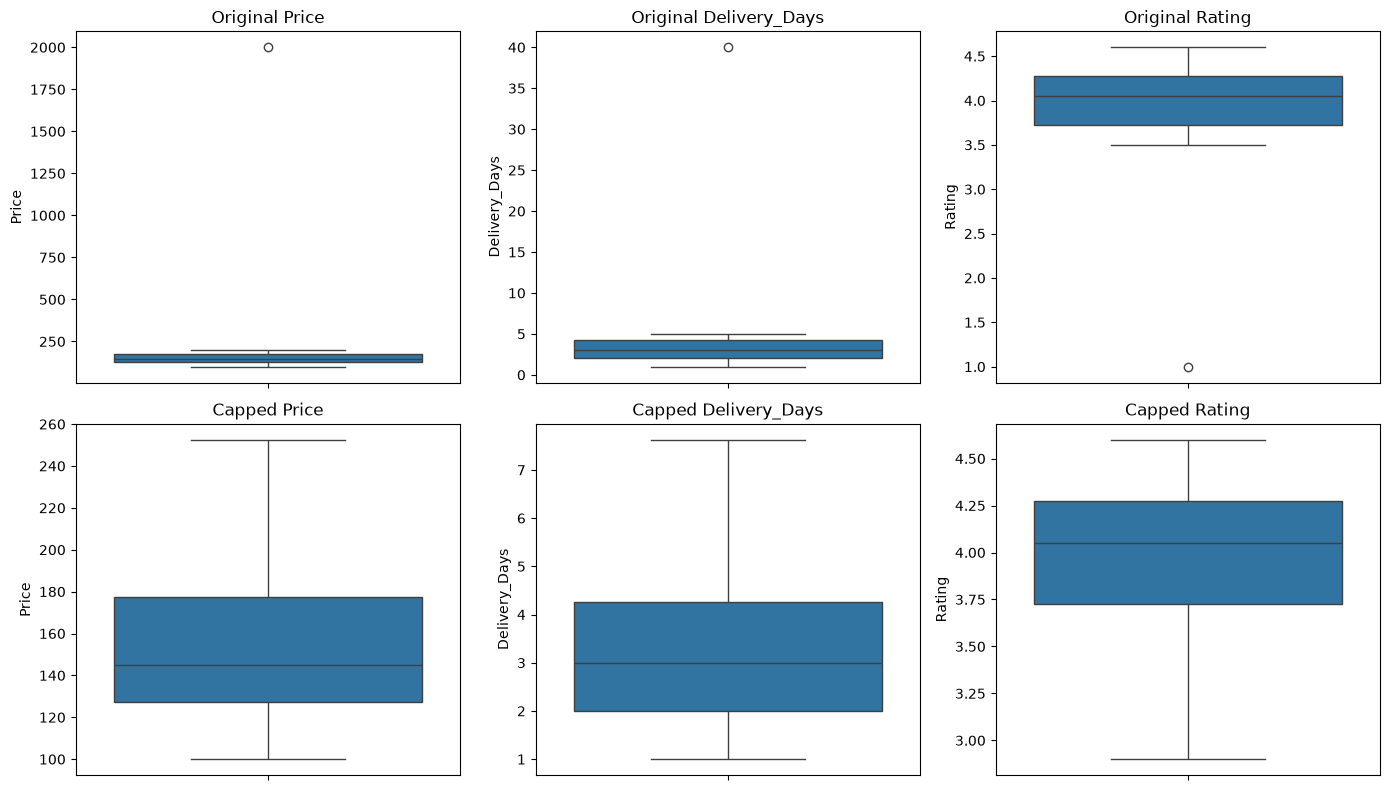

In [8]:

# Compare row counts
print("Original Rows:", len(df))
print("Removed Rows:", len(removed_df))
print("Capped Rows:", len(capped_df))

# Compare descriptive statistics
print("\nOriginal Statistics:")
print(df[["Price", "Delivery_Days", "Rating"]].describe())

print("\nRemoved Statistics:")
print(removed_df[
    ["Price", "Delivery_Days", "Rating"]
].describe())

print("\nCapped Statistics:")
print(capped_df[
    ["Price", "Delivery_Days", "Rating"]
].describe())

# Compare number of outliers
print("\nOutlier Counts:")
print(remove_report[
    ["Column", "Outlier_Count"]
])

# Visualize original and capped data
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

columns = ["Price", "Delivery_Days", "Rating"]

for i, col in enumerate(columns):

    sns.boxplot(y=df[col], ax=axes[0, i])
    axes[0, i].set_title("Original " + col)

    sns.boxplot(y=capped_df[col], ax=axes[1, i])
    axes[1, i].set_title("Capped " + col)

plt.tight_layout()
plt.show()
